In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import StandardScaler
import umap
from sklearn.cross_decomposition import CCA

# ==========================================
# 0. Path Definitions & Style
# ==========================================
BASE_DIR = Path('/kyb/agpd/wwang/data/')
OUT_DIR = Path('/kyb/agpd/wwang/sst-pomdp/outputs/')

# LaTeX Display Names for Plots
PARAM_DISPLAY_NAMES = {
    'q_d_n': r"$\chi'$",
    'q_d': r"$\chi$",
    'q_s_n': r"$\sigma'$",
    'q_s': r"$\sigma$",
    'cost_stop_error': r"$c_{\mathrm{se}}$",
    'cost_time': r"$c_t$",
}

Data loaded. Shape: (5918, 16)
Canonical Correlations: [np.float64(0.1377161120789869), np.float64(0.05892962984437753), np.float64(0.023143922330059557), np.float64(0.021954268492345934), np.float64(0.0063068087564076185)]


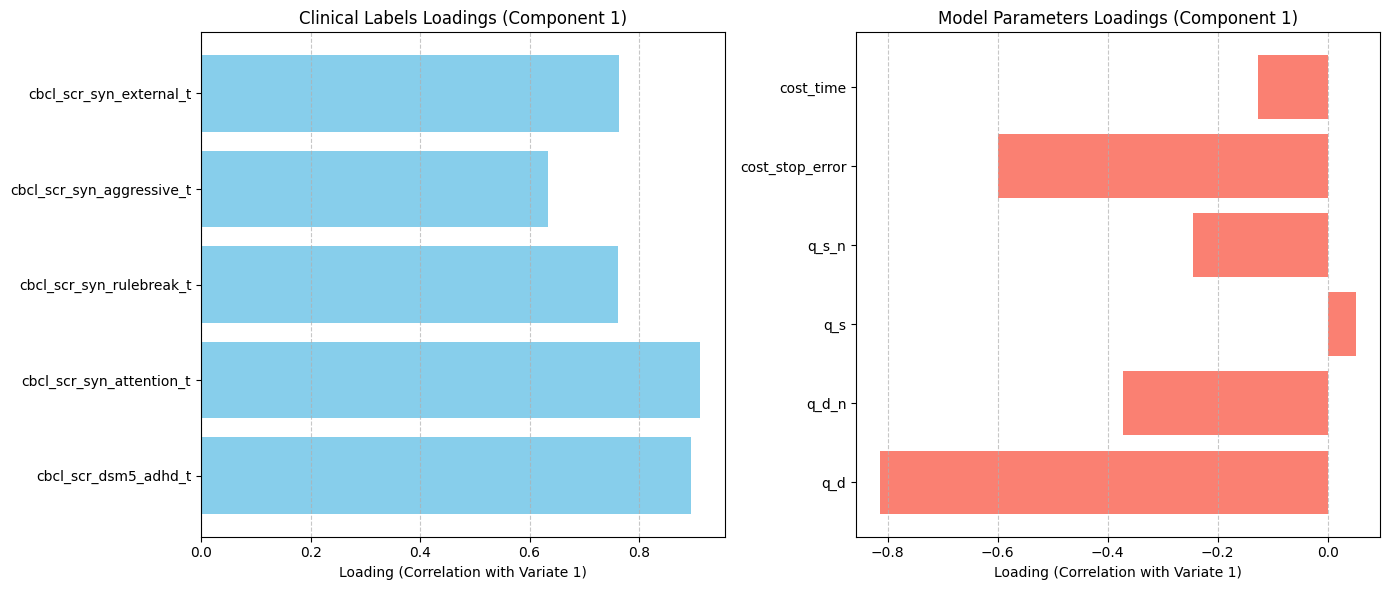

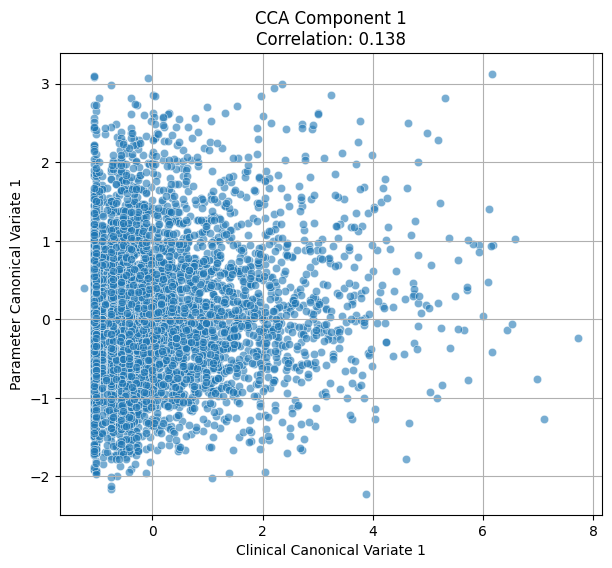

In [3]:
def prepare_data():
    # 1. Load Clinical Labels (CBCL)
    # We load mh_p_cbcl.csv for the clinical labels you requested
    df_cbcl = pd.read_csv(BASE_DIR / 'mh_p_cbcl.csv', low_memory=False)
    
    # Clean Subject ID (remove 'NDAR_' prefix to match other files)
    df_cbcl['subject_id'] = df_cbcl['src_subject_id'].str.replace('NDAR_', '')
    
    # Map 'eventname' to 'year' (assuming baseline matches)
    event_map = {
        'baseline_year_1_arm_1': 'baseline',
        '2_year_follow_up_y_arm_1': '2_year', 
        # Add other mappings if needed
    }
    df_cbcl['year'] = df_cbcl['eventname'].map(event_map)
    
    clinical_cols = [
        'cbcl_scr_dsm5_adhd_t', 
        'cbcl_scr_syn_attention_t', 
        'cbcl_scr_syn_rulebreak_t', 
        'cbcl_scr_syn_aggressive_t',
        'cbcl_scr_syn_external_t'
    ]
    # Filter for relevant columns and drop rows with missing values
    df_cbcl = df_cbcl[['subject_id', 'year'] + clinical_cols].dropna()

    # 2. Load Parameters (Posterior Summary)
    # Based on your snippet. 
    # NOTE: Since this file was missing in the upload, ensure it exists in your directory.
    df_post = pd.read_csv(OUT_DIR / 'posterior_summary.csv')
    df_post['year'] = df_post['subject_year'].astype(str)
    
    # Pivot to get parameters as columns
    df_post_pivot = df_post.pivot_table(index=['subject_id', 'year'], 
                                        columns='param', values='mean').reset_index()
    
    param_cols = ['q_d', 'q_d_n', 'q_s', 'q_s_n', 'cost_stop_error', 'cost_time']

    # 3. Load Stats (Filter)
    df_stats = pd.read_csv(OUT_DIR / 'stats_beh_full.csv')
    df_stats['year'] = df_stats['year'].astype(str)
    
    # 4. Merge Dataframes
    # Use inner merge to keep only subjects present in all files
    df = pd.merge(df_stats[['subject_id', 'year']], df_cbcl, on=['subject_id', 'year'], how='inner')
    df = pd.merge(df, df_post_pivot, on=['subject_id', 'year'], how='inner')
    
    # Final cleanup
    df_clean = df.dropna(subset=clinical_cols + param_cols).copy()
    
    return df_clean, clinical_cols, param_cols

# --- Main Execution ---

# Load data
# Note: Ensure all CSV files are in the current directory or update OUT_DIR
try:
    df, clinical_cols, param_cols = prepare_data()
    print(f"Data loaded. Shape: {df.shape}")

    # Standardize the data (important for CCA)
    scaler_X = StandardScaler()
    scaler_Y = StandardScaler()
    
    X = df[clinical_cols]
    Y = df[param_cols]
    
    X_sc = scaler_X.fit_transform(X)
    Y_sc = scaler_Y.fit_transform(Y)

    # Run CCA
    # n_components is limited by the smaller dimension
    n_components = min(len(clinical_cols), len(param_cols))
    cca = CCA(n_components=n_components)
    cca.fit(X_sc, Y_sc)

    # Transform data to canonical space
    X_c, Y_c = cca.transform(X_sc, Y_sc)

    # Calculate Canonical Correlations
    corrs = [np.corrcoef(X_c[:, i], Y_c[:, i])[0, 1] for i in range(n_components)]
    print("Canonical Correlations:", corrs)

    # --- Visualization ---
    
    # Calculate Loadings (Correlation between original variables and canonical variate)
    # Using the first component (index 0)
    x_loadings = [np.corrcoef(X_sc[:, i], X_c[:, 0])[0, 1] for i in range(X.shape[1])]
    y_loadings = [np.corrcoef(Y_sc[:, i], Y_c[:, 0])[0, 1] for i in range(Y.shape[1])]

    plt.figure(figsize=(14, 6))

    # Plot Clinical Loadings
    plt.subplot(1, 2, 1)
    y_pos_x = np.arange(len(clinical_cols))
    plt.barh(y_pos_x, x_loadings, align='center', color='skyblue')
    plt.yticks(y_pos_x, clinical_cols)
    plt.xlabel('Loading (Correlation with Variate 1)')
    plt.title('Clinical Labels Loadings (Component 1)')
    plt.grid(axis='x', linestyle='--', alpha=0.7)

    # Plot Parameter Loadings
    plt.subplot(1, 2, 2)
    y_pos_y = np.arange(len(param_cols))
    plt.barh(y_pos_y, y_loadings, align='center', color='salmon')
    plt.yticks(y_pos_y, param_cols)
    plt.xlabel('Loading (Correlation with Variate 1)')
    plt.title('Model Parameters Loadings (Component 1)')
    plt.grid(axis='x', linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.savefig('cca_loadings.png')
    plt.show()

    # Scatter Plot of Component 1
    plt.figure(figsize=(7, 6))
    sns.scatterplot(x=X_c[:, 0], y=Y_c[:, 0], alpha=0.6)
    plt.xlabel(f'Clinical Canonical Variate 1')
    plt.ylabel(f'Parameter Canonical Variate 1')
    plt.title(f'CCA Component 1\nCorrelation: {corrs[0]:.3f}')
    plt.grid(True)
    plt.savefig('cca_scatter.png')
    plt.show()

except FileNotFoundError as e:
    print(f"Error: {e}. Please ensure all CSV files (including posterior_summary.csv) are present.")
except Exception as e:
    print(f"An error occurred: {e}")